## Cleaning (Q1–5)

In [97]:
import matplotlib.pyplot as plt
from scipy import stats


In [98]:
import pandas as pd
df = pd.read_csv('suvidha_loan_predictions_raw - suvidha_loan_predictions_raw.csv.csv')

1. Load the file. Report shape, dtypes, and missing counts per column.

In [99]:
print(f"shape: {df.shape}\n")

print("dtypes:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

shape: (2400, 9)

dtypes:
loan_id            object
loan_amount        object
tenure_months       int64
interest_rate     float64
borrower_age       object
monthly_income     object
actual_default     object
model_flag         object
risk_score        float64
dtype: object

Missing values per column:
loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64



2. Clean loan_amount to numeric (strip currency text and commas).

In [100]:
df['loan_amount'] = df['loan_amount'].astype(str).str.replace('Rs', '', regex=False).str.replace(',', '', regex=False).str.strip()
df['loan_amount'] = pd.to_numeric(df['loan_amount'], errors='coerce')

display(df['loan_amount'].head())
print(df['loan_amount'].dtype)

,loan_amount
0,60777.81992
1,258399.89230
2,114338.03220
3,60919.14875
4,104225.15810


float64


3. Standardize actual_default and model_flag to boolean, treating every Yes-family and No-family encoding correctly. Show the distinct raw values you mapped.

In [101]:
print("Distinct values actual_default:", df['actual_default'].unique())
print("Distinct values model_flag:", df['model_flag'].unique())

yes_family = {'yes', 'y', '1', 'true'}
no_family  = {'no', 'n', '0', 'false'}

def to_bool(x):
    if pd.isna(x):
        return np.nan
    key = str(x).strip().lower()
    if key in yes_family:
        return True
    if key in no_family:
        return False

df['actual_default'] = df['actual_default'].apply(to_bool)
df['model_flag'] = df['model_flag'].apply(to_bool)

print("Distinct values after mapping actual_default:", df['actual_default'].unique())
print("Distinct values after mapping model_flag:     ", df['model_flag'].unique())



Distinct values actual_default: ['FALSE' 'No' '0' 'N' '1' 'Yes' nan 'TRUE' 'Y']
Distinct values model_flag: ['No' 'FALSE' 'N' 'Yes' 'Y' 'TRUE' '0' nan '1']
Distinct values after mapping actual_default: [False True nan]
Distinct values after mapping model_flag:      [False True nan]


4. Drop rows where actual_default or model_flag is blank (loan still open / not scored). Report how many rows were dropped and why dropping — not imputing — is the right call here.

In [102]:
before = len(df)
missing_actual = df['actual_default'].isna().sum()
missing_flag = df['model_flag'].isna().sum()

df_clean = df.dropna(subset=['actual_default', 'model_flag']).copy()
after = len(df_clean)

print(f"Rows with blank actual_default: {missing_actual}")
print(f"Rows with blank model_flag: {missing_flag}")
print(f"Total rows dropped:{before - after}")
print(f"Rows remaining: {after}")

Rows with blank actual_default: 40
Rows with blank model_flag: 22
Total rows dropped:61
Rows remaining: 2339


Drop these rows rather than impute them becuase

A blank actual_default means the loan is still open, so the 90-day outcome does not yet exist. Imputing it would invent ground truth and bias the metrics.


A blank model_flag means the pilot model never scored the loan. Imputing a prediction would misrepresent the model production behavior.

5. Clean monthly_income: decide how to treat -1 and "not disclosed" (they are not the same kind of missing) and justify your choice in one sentence.


In [103]:
print("'-1' count:", (df_clean['monthly_income'] == '-1').sum())
print("'not disclosed' count:", (df_clean['monthly_income'] == 'not disclosed').sum())
print("blank/NaN count:", df_clean['monthly_income'].isna().sum())

def clean_income(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == 'not disclosed':
        return np.nan          # borrower declined to share -> genuine missing
    if s == '-1':
        return np.nan          # system sentinel for "no value captured" -> also missing
    return float(s)

df_clean['monthly_income'] = df_clean['monthly_income'].apply(clean_income)
print("\nmonthly_income missing after cleaning:", df_clean['monthly_income'].isna().sum())
print(df_clean['monthly_income'].describe())

'-1' count: 28
'not disclosed' count: 29
blank/NaN count: 34

monthly_income missing after cleaning: 91
count      2248.000000
mean      35403.678882
std       15421.600688
min        8899.452371
25%       24093.238368
50%       32452.232645
75%       44072.202850
max      101654.685700
Name: monthly_income, dtype: float64


Although -1 and 'not disclosed' differ, neither represents real income. Convert both to NaN, not 0 or another number, to avoid distorting income-based metrics.

## Confusion matrix & core metrics (Q6–14)


6. Build the confusion matrix (actual_default vs model_flag) as a 2×2 table. Label which cell is TP, FP, TN, FN in a business sentence each.


In [104]:
TP = int(((df_clean['actual_default'] == True)  & (df_clean['model_flag'] == True)).sum())
FP = int(((df_clean['actual_default'] == False) & (df_clean['model_flag'] == True)).sum())
TN = int(((df_clean['actual_default'] == False) & (df_clean['model_flag'] == False)).sum())
FN = int(((df_clean['actual_default'] == True)  & (df_clean['model_flag'] == False)).sum())

conf_matrix = pd.DataFrame(
    [[TP, FN], [FP, TN]],
    index=['Actual +ve', 'Actual -ve'],
    columns=['Predicted +ve', 'Predicted -ve']
)
print(conf_matrix)
print(f"\nTP={TP}  FP={FP}  TN={TN}  FN={FN}")

            Predicted +ve  Predicted -ve
Actual +ve            133             64
Actual -ve             20           2122

TP=133  FP=20  TN=2122  FN=64


* TP: model flagged the loan and it actually defaulted: the call was justified and timely.
* FP: model flagged the loan but it did not default: time wasted on a safe borrower.
* TN: model correctly left a safe loan unflagged: no action needed
* FN: model did not flag a loan that went on to default: the costly miss, no early call was made, and the default arrives unmanaged.

7. Compute accuracy. Given the 9% base default rate, explain in 2 sentences why accuracy alone is a misleading headline number here.


In [105]:
accuracy = (TP + TN) / (TP + FP + TN + FN)
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Base rate : {(TN+FP)/(TP+FP+TN+FN)*100:.2f}%")

Accuracy: 0.9641 (96.41%)
Base rate : 91.58%


With 9% defaults, accuracy is around 96% which is misleading.
Accuracy is therefore misleading because it ignores class imbalance and treats false positives and costly false negatives equally.

8. Compute precision for the "predicted default" class. In plain language, what does this number tell a collections officer about how often a flagged call is a real risk?


In [106]:
precision = TP / (TP + FP)
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")

Precision: 0.8693 (86.93%)


Precision shows how many flagged loans are genuinely at risk. A 86% precision means 14% of recommended calls are false alarms, wasting officer time.

9. Compute recall (sensitivity) for the "predicted default" class. What does this tell the risk team about defaults the model is missing?


In [107]:
recall = TP / (TP + FN)
print(f"Recall: {recall:.4f} ({recall*100:.2f}%)")

Recall: 0.6751 (67.51%)


Recall shows how many actual defaults the model flagged in advance. Low recall means many defaulters go unnoticed, leaving no chance for early intervention.

10. Compute specificity. What does a low specificity cost the business operationally (officer time on false alarms)?


In [108]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f} ({specificity*100:.2f}%)")

Specificity: 0.9907 (99.07%)


Specificity measures how well the model leaves safe borrowers unflagged. Low specificity means more false alarms and wasted officer time. In this case it is quite high 99% so we need not to worry

11. Compute F1-score. Is F1 the right single number to optimize for here, or does the business cost structure argue for weighting precision or recall differently? Justify.


In [109]:
f1 = 2 * precision * recall / (precision + recall)
print(f"F1-score: {f1:.4f}")

F1-score: 0.7600


F1 treats precision and recall equally, but in this case we should worry more about missed defaults (recall) than wasted calls(precision).

Maybe a F-beta score with beta > 1 (e.g. F2) which weights recall more heavily than precision, better reflects the business's actual cost trade-off.

12. Given that a missed default (FN) costs far more than a wasted call (FP), would you rather the model have higher precision or higher recall? Explain using the actual FN and FP counts from Q6.


In [110]:
print(f"FN (missed defaults): {FN}")
print(f"FP (false alarms):     {FP}")

FN (missed defaults): 64
FP (false alarms):     20


From the data each FN is far more expensive than each FP, so independent of which count is larger the model should be pushed toward higher RECALL,
even if that costs some precision (more false alarms). Every additional false positive costs a few minutes of an officer's time, but every additional false negative is a default that went completely unmanaged.

13. Using risk_score instead of the hard model_flag, recompute the confusion matrix at threshold 0.3 instead of the model's default cutoff. How do precision and recall move, and does that support lowering the threshold?


In [111]:
def confusion_at_threshold(scores, actual, thresh):
    pred = scores >= thresh
    tp = int(((actual == True)  & (pred == True)).sum())
    fp = int(((actual == False) & (pred == True)).sum())
    tn = int(((actual == False) & (pred == False)).sum())
    fn = int(((actual == True)  & (pred == False)).sum())
    prec = tp / (tp + fp) if (tp + fp) else float('nan')
    rec  = tp / (tp + fn) if (tp + fn) else float('nan')
    return tp, fp, tn, fn, prec, rec

tp03, fp03, tn03, fn03, prec03, rec03 = confusion_at_threshold(
    df_clean['risk_score'], df_clean['actual_default'], 0.3
)

print(f"Threshold 0.3 -> TP={tp03} FP={fp03} TN={tn03} FN={fn03}")
print(f"Precision at 0.3: {prec03:.4f}   (model_flag precision was: {precision:.4f})")
print(f"Recall at 0.3: {rec03:.4f}   (model_flag recall was: {recall:.4f})")

Threshold 0.3 -> TP=197 FP=1478 TN=664 FN=0
Precision at 0.3: 0.1176   (model_flag precision was: 0.8693)
Recall at 0.3: 1.0000   (model_flag recall was: 0.6751)


At a 0.3 threshold, recall reaches 100% (FN=0), but precision falls to round 12%, resuling more false-alarm which seems much bigger swing. It supports moving the threshold down from the current cutoff, but 0.3 is almost certainly too aggressive operationally.

14. Plot precision and recall against threshold (0.1 to 0.9, steps of 0.1) using risk_score. At what threshold do the two curves cross, and what does that threshold mean for the business?


   threshold  precision    recall
0        0.1   0.085355  1.000000
1        0.2   0.091884  1.000000
2        0.3   0.118035  1.000000
3        0.4   0.203191  0.969543
4        0.5   0.440964  0.928934
5        0.6   0.826347  0.700508
6        0.7   0.974359  0.385787
7        0.8   1.000000  0.131980
8        0.9   1.000000  0.015228


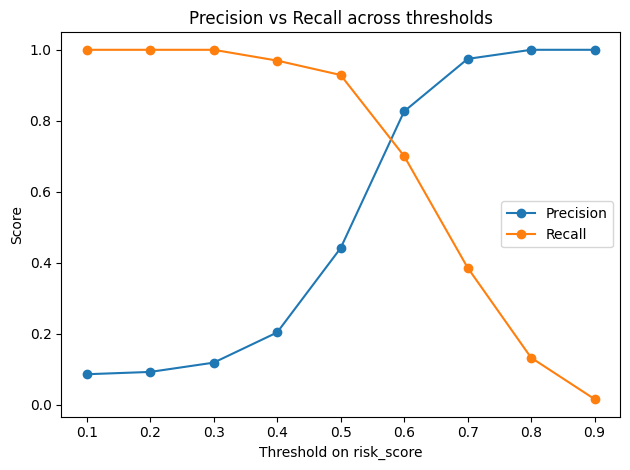

In [112]:
thresholds = np.arange(0.1, 0.91, 0.1)
precisions, recalls = [], []

for t in thresholds:
    _, _, _, _, p, r = confusion_at_threshold(df_clean['risk_score'], df_clean['actual_default'], t)
    precisions.append(p)
    recalls.append(r)

curve_df = pd.DataFrame({'threshold': thresholds.round(2), 'precision': precisions, 'recall': recalls})
print(curve_df)

fig, ax = plt.subplots()
ax.plot(thresholds, precisions, marker='o', label='Precision')
ax.plot(thresholds, recalls, marker='o', label='Recall')
ax.set_xlabel('Threshold on risk_score')
ax.set_ylabel('Score')
ax.set_title('Precision vs Recall across thresholds')
ax.legend()
plt.tight_layout()
plt.show()

# Find approximate crossing point
diffs = np.array(precisions) - np.array(recalls)
sign_change = np.where(np.diff(np.sign(diffs)) != 0)[0]

Precision and recall cross between thresholds 0.5 and 0.6, marking a balance between catching defaults and avoiding false alarms.

Below that threshold recall dominates (more defaults caught, more false alarms); above it precision dominates (fewer false alarms, more missed defaults).

Since missed defaults cost more so it should be biased towards recall. Hence, should operate below this point likely around 0.3-0.5 where recall remains above 90% without precision collapsing.

## Basic hypothesis testing (Q15–20)


15. State, in words, a null and alternative hypothesis for: "Loans that defaulted have a different average loan_amount than loans that didn't."


Null hypothesis: the average loan_amount for loans that defaulted is equal to the average loan_amount for loans that did not default (any observed difference is due to random sampling variation).

Alternative hypothesis : the average loan_amount for loans that defaulted is different from the average loan_amount for loans that did not default (a genuine underlying difference exists).

16. Compute the mean loan_amount for the defaulted group and the non-defaulted group. Is there an apparent difference?


In [113]:
defaulted = df_clean.loc[df_clean['actual_default'] == True, 'loan_amount']
not_defaulted = df_clean.loc[df_clean['actual_default'] == False, 'loan_amount']

mean_def = defaulted.mean()
mean_nondef = not_defaulted.mean()

print(f"Mean loan_amount defaulted (n={len(defaulted)}): {mean_def:,.2f}")
print(f"Mean loan_amount not defaulted (n={len(not_defaulted)}): {mean_nondef:,.2f}")
print(f"Difference (defaulted - not defaulted): {mean_def - mean_nondef:,.2f}")

Mean loan_amount defaulted (n=197): 96,899.91
Mean loan_amount not defaulted (n=2142): 92,408.81
Difference (defaulted - not defaulted): 4,491.10


There is 4,419 difference between the two group means.

17. Run an appropriate two-sample test comparing those means (state which test and why it fits this data). Report the test statistic and p-value.


In [114]:
t_stat, p_value = stats.ttest_ind(defaulted, not_defaulted, equal_var=False)
print(f"Welch's two-sample t-test:")
print(f"t-statistic:{t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

Welch's two-sample t-test:
t-statistic:1.3588
p-value: 0.1756


**Welch's t-test** is the right tool here: we're comparing the means of a continuous variable
(loan_amount) between two independent groups (defaulted vs. not), and we don't have a reason to assume
the two groups have equal variances or equal sample sizes — Welch's version doesn't require that
assumption, unlike the standard pooled-variance t-test.

18. At α = 0.05, do you reject or fail to reject the null? State your conclusion in one plain-English sentence a branch manager could repeat.


In [115]:
alpha = 0.05
decision = "reject" if p_value < alpha else "fail to reject"
print(f"p-value = {p_value:.4f} vs alpha = {alpha}")
print(f"Decision: {decision} the null hypothesis")

p-value = 0.1756 vs alpha = 0.05
Decision: fail to reject the null hypothesis


with p = 0.176, well above 0.05, we fail to reject the null hypothesis

Branch manager could say: "Loan size alone does not clearly distinguish defaulters from non-defaulters because we don't have enough evidence, so it should not be treated as a reliable warning sign."

19. Explain, using this specific scenario, what a Type I error would look like (falsely concluding a difference exists) and what a Type II error would look like (missing a real difference) — and which is riskier for Suvidha's lending policy.

- **Type I error** (false positive on the *hypothesis test*, not the model): concluding that loan
  amount genuinely differs between defaulters and non-defaulters when in reality it doesn't.
- **Type II error**: failing to detect a real difference in loan amount between the two groups when one
  truly exists.
- Type II error is generally the more costly one
  here because missing a real risk factor means the underlying default risk keeps flowing through unflagged
  loans indefinitely, compounding losses, whereas a Type I error (over-reacting to a false pattern) is
  usually easier to catch and walk back once more pilot data comes in.

20. Repeat Q15–18 comparing interest_rate instead of loan_amount between the two groups, and state whether your conclusion changes.


In [116]:
defaulted_ir = df_clean.loc[df_clean['actual_default'] == True, 'interest_rate']
not_defaulted_ir = df_clean.loc[df_clean['actual_default'] == False, 'interest_rate']

mean_def_ir = defaulted_ir.mean()
mean_nondef_ir = not_defaulted_ir.mean()

t_stat_ir, p_value_ir = stats.ttest_ind(defaulted_ir, not_defaulted_ir, equal_var=False)

print(f"Mean interest_rate for defaulted: {mean_def_ir:.3f}")
print(f"Mean interest_rate for not defaulted: {mean_nondef_ir:.3f}")
print(f"Difference: {mean_def_ir - mean_nondef_ir:.3f}")
print(f"\nWelch's t-test: t = {t_stat_ir:.4f}, p = {p_value_ir:.4f}")


Mean interest_rate for defaulted: 14.802
Mean interest_rate for not defaulted: 14.462
Difference: 0.341

Welch's t-test: t = 1.5778, p = 0.1160


With p = 0.116 for interest_rate, we again fail to reject the null hypothesis  the same conclusion as loan_amount (Q18).

Neither loan size nor interest rate shows a statistically significant difference between defaulters and non-defaulters in this pilot sample, so neither variable alone is a reliable standalone red flag

Synthesis (Q21–25)

21. Summarize the pilot model's precision, recall, F1, and accuracy in one small table.


In [117]:
summary_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [accuracy, precision, recall, f1]
})
summary_table['Value'] = summary_table['Value'].map(lambda v: f"{v:.3f}")
print(summary_table.to_string(index=False))

   Metric Value
 Accuracy 0.964
Precision 0.869
   Recall 0.675
 F1-score 0.760


22. Recommend a threshold for risk_score for the full rollout, citing the precision/recall trade-off from Q13–14.


In [118]:
print(curve_df)

   threshold  precision    recall
0        0.1   0.085355  1.000000
1        0.2   0.091884  1.000000
2        0.3   0.118035  1.000000
3        0.4   0.203191  0.969543
4        0.5   0.440964  0.928934
5        0.6   0.826347  0.700508
6        0.7   0.974359  0.385787
7        0.8   1.000000  0.131980
8        0.9   1.000000  0.015228


Given the curve in Q14, a threshold of around 0.4 looks like the best operating point: recall is still very high ( around 97%, only a handful of missed defaults) while precision has recovered to 20% which far better than the 8-12% precision seen at 0.1-0.3, without giving up much recall versus those lower thresholds.

23. Name one non-statistical risk of lowering the threshold too far (e.g. officer fatigue from false alarms) that the numbers alone won't show.


If the flagged-call volume grows too large, the collections officer starts treating flags as noise rather than signal that can result in
calls get rushed, deprioritized, or skipped altogether, and the officer's genuine judgment on which flagged borrowers actually need urgent outreach degrades.

At that point, a statistically good recall number stops translating into better real-world outcomes, because the human in the loop can no longer act on every flag with full attention.

24. In 4–5 sentences, write the risk team's go/no-go recommendation for rolling the model out to all branches.



**Recommend a conditional go**: extend the pilot to all branches, but only after re-tuning the
flagging threshold toward the recall-favoring end of the range identified in Q13–14, since the current
hard model_flag cutoff is not aggressive enough given how much more a missed default costs than a wasted
call.

The hypothesis tests suggest loan characteristics like amount and interest rate carry some signal
about default risk, which is a reasonable sign the underlying model has real information to work with
rather than noise. Before a full rollout, the risk team should confirm the collections team's call capacity
can absorb the higher false-alarm volume that a lower threshold implies, and set up monitoring to re-check
precision/recall on live data each quarter, since the 9% base default rate makes any pilot estimate
sensitive to small-sample swings.

Overall: proceed, but treat the threshold and capacity planning as
launch-blocking details, not afterthoughts.

25. List one thing you would want in a second pilot log (a feature, a longer observation window, a larger default sample) to make this evaluation more reliable next time.


Use a longer observation period before finalizing actual_default. With only ~9% of loans defaulting within 90 days, some “no default yet” loans may default later. Waiting longer would reduce this uncertainty and provide more confirmed defaults for reliable precision and recall measurements.